---
title: Solving LinkedIn Zip by Linear Optimization
short_title: How to Solve Zip
date: 2025-09-17
---

![Zip Banner](../assets/how-to-solve/zip/banner.jpg)

<a href="https://mybinder.org/v2/gh/rodrigo-cl-porto/LinkedIn-Games-Linear-Optimization-Solvers/binder?urlpath=lab/tree/notebooks/zip.ipynb">
  <img src="https://mybinder.org/badge_logo.svg" alt="Launch Binder" width="20%" >
</a>

# How to Play Zip

:::{figure} ../assets/how-to-solve/zip/example.mp4
:label: zip-example
:alt: Zip Example
:align: center
:width: 60%

Example of a Zip game board (_Source: [LinkedIn Zip](https://www.linkedin.com/games/zip/)_)

:::

The board of Zip is made up with some numbered squares and walls (walls are optional).

Objective
: To trace a single path that runs through all the squares on the board.

Rule
: The path must move through numbered squares in ascending order, starting from square number 1 to the one with the highest number.

# Problem Modeling

The best way to solve the game is to consider the squares as nodes in a **directed graph** (digraph), where each node has a set of pairs of edges that arrive at and depart from the nodes, as shown in the following figure.

:::{figure} ../assets/how-to-solve/zip/graph-model.png
:label: zip-graph-model
:align: center
:width: 60%
Zip game modeled on a directed graph. _Source: created by the author_
:::

Considering this graph model, it was enacted the Abstract LO Model by defining its following components:

- **Ranges**
- **Sets**
- **Decision variables**
- **Parameter**
- **Objective function**
- **Constraints**

## Ranges

To properly formulate the LO model, we will start from the premise that the squares on the board will be the Cartesian product of the ranges $I$ of rows and $J$ of columns present on the board. In addition, it is necessary to have defined an interval $K$ for the set of numbered squares.

$I = \{1, \cdots, n\}$
: The row range, where $n$ is the total number of rows (in this case, $n = 6$)

$J = \{1, \cdots, m\}$
: The column range, where $m$ is the total number of columns (in this case, $m = 6$ as well).

## Sets

The definition of the sets will be more than fundamental to reducing the complexity of the model, as we will avoid having to deal with numerous exceptions. From the ranges determined previously, we can define the set of vertices ($V$) and edges ($E$) existing in the network logic. In addition to these, it is also necessary to consider the subsets of numbered vertices ($N$) and blocked edges ($W$), since, in some instances of Zip game, there may be walls between two squares that prevent the path from being traced between them.

$V = \{(i,j) \mid \forall i \in I, \forall j \in J \}$
: Set of all squares (vertices). There must be at least 2 vertices in the grid, as it is only possible to trace a path with an initial and a final square. Therefore, $|V| \ge 2$

$E = \begin{array}{lr} \{((i,j), (i+1,j)) \mid (i,j) \in V, i + 1 \in I \} & \cup \\ \{((i,j), (i-1,j)) \mid (i,j) \in V, i - 1 \in I \} & \cup \\ \{((i,j), (i,j+1)) \mid (i,j) \in V, j + 1 \in J \} & \cup \\ \{((i,j), (i,j-1)) \mid (i,j) \in V, j - 1 \in J \} & \end{array}$
: Set of all edges present in the graph. Its definition is a bit more complex as it is necessary to clarify that, for each vertex, there will only be edges between neighbors immediately to the left, immediately to the right, immediately above, and immediately below it, if they exist.

$K \subseteq V$
: Set of numbered squares, which will consist of a set of all vertices indexed by a number on board game.

$W \subset E$
: Set of blocked edges (walls) that may appear on the grid.

## Decision Variables

By using the network logic already presented, it is possible to define the edges as binary decision variables $x_{ijrs}$, which again makes our LOP a **BLOP**. In addition to $x_{ijrs}$, variables $u_{ij}$ will also be considered, representing the absolute ordinal position of the square $(i,j)$ within the path (these variables will be better explained later).

$x_{ijrs} \in \B$
: $x_{ijrs}=1$, if the edge that starts from square $(i,j)$ and arrives at square $(r,s)$ is part of the path
: $x_{ijrs}=0$, otherwise

$u_{ij} \in \mathbb{N}$
: Absolute ordinal positions of the squares $(i,j)$ within the path.

## Parameters

$ k_{ij} \in \{1, \cdots, |K|\}, \qquad \forall (i,j) \in K $
: For each numbered board square in $K$ set, it'll be defined a integer $k_{ij}$ that matches its number displayed on game board.

## Objective Function

Once again, our problem does not have a function to be optimized, since we only want to find a solution that fulfills all the rules of the game. Therefore, a Zip BLOP is a **feasibility problem**, and the objective function of the model consists of maximizing (or minimizing) an arbitrary constant.

$$ \text{Min} \quad C $$

## Constraints

Decision variables domain constraints
: First, let's not forget to define our variables $x_{ijrs}$ as binary and the variables $u_{ij}$ as non-negative real numbers. To simplify, whenever possible, we can replace the notation $x_{ijrs}$ with $x_{vw}$ and $u_{ij}$ with just $u_v$, since the tuple $(i,j) = v$ always refers to some vertex belonging to $V$ set.
: $$ \begin{array}{} x_{v,w} \in \B, \qquad \forall (v,w) \in E \\ u_v \ge 1, \qquad \forall v \in V \end{array} $$

Blocked edges constraints
: If there is a wall between a pair of squares, then the sum of the edges connecting those ones must be equal to 0.
: $$ x_{v,w} + x_{w,v} = 0, \qquad \forall (v,w) \in W $$

Continuity constraints
: Since it is only possible to enter and exit a node once (except for the initial and destination nodes), then we will have the following:

    Outgoing-Edges Constraints
    : The sum of the edges emanating from a node must equal 1 (except for the destination square).
    : $$ \sum_{w \in V}{x_{vw}} = 1, \qquad \forall v \in V \backslash \{v:k_v=|K|\}: (v,w) \in E $$

    Incoming-Edges Constraints
    : The sum of the edges arriving at a node must equal 1 (except for the initial square).
    : $$ \sum_{v \in V}{x_{vw}} = 1, \qquad \forall w \in V \backslash \{w:k_w=1\}: (v,w) \in E $$

    Arrival Square Constraint
    : The sum of the edges emanating from the destination node must be 0.
    : $$ \sum_{w \in V}{x_{vw}} = 0, \qquad (v,w) \in E, k_v = |K| $$

    Starting Square Constraint
    : The sum of the edges arriving at the initial node must be 0.
    : $$ \sum_{v \in V}{x_{vw}} = 0, \qquad (v,w) \in E, k_w = 1 $$
    
    :::{note}
    It only makes sense to apply the last two constraints if the edges entering the initial square and exiting the destination square have already been removed from the graph, but I included them because I started from a model where the initial and destination nodes can be changed from game to game without needing to alter the graph's basic structure.
    :::

:::{hint} The Miller-Tucker-Zemlin formulation
If it were a complete digraph, where all vertices were connected to each other, the number of constraints needed to guarantee the elimination of any cycle would be on the exponential order of $2^{|V|+1}$. That is, for our graph of 36 squares, this would represent, in the worst case, formulating a BLOP model with no less than 2 {sup}`37` = 137,438,953,472 constraints!

Furthermore, since a square can only be visited once, it also makes sense to include a set of constraints to prevent the selection of a pair of edges that enter and exit the same square, forming a cycle (sub-route) in the graph. However, in addition to the constraints for eliminating cycles composed of 2 decimal places, it would also be necessary to include constraints to prevent cycles of 3, 4... up to 34 decimal places in our case, which would require a monstrous number of constraints.

Fortunately, the number of constraints for eliminating cycles is immensely reduced if the **Miller-Tucker-Zemlin** formulation is used, shown below.
:::

Subroute Elimination Constraints
: The advantage of the MTZ formulation is that the number of constraints to be included to guarantee subroute elimination is equal to $|E| = 4nm - 2n - 2m$, that is, the number of edges in the graph. Thus, the number of constraints grows linearly as a function of the number of edges, instead of exponentially as a function of the number of vertices. For it to work, it requires the addition of more decision variables (the previously mentioned $u_{ij}$), which represent the absolute ordinal position of square $(i,j)$ within the path.

    Position of Starting Square Constraint
    : First, the position of the starting square must be equal to 1, since it will always be the first position on the path.
    : $$u_v = 1: \qquad k_v = 1$$

    MTZ Constraints
    : Then, the positions of the remaining squares on the board should be given as follows.
    : $$u_w \ge u_v + 1 - M(1 - x_{vw}), \qquad \forall (v,w) \in E: w \in V \backslash \{w:k_w=1\}$$

    :::{note} How big must $M$ be?
    In this formulation, the big $M$ corresponds to a constant whose value is large enough to cover all possible positions a square can assume on the path. Therefore, a sufficiently large value of $M$ must correspond to $|V|$, that is, $M$ must be at least equal to the number of squares on the board (which in our particular case is 36).
    ```{math}
    :enumerated: false
    M \ge |V|
    ```
    :::

    Positon of Arrival Square Constraint
    : Although not necessary, one can restrict the position of the arrival square to be equal to the number of squares on the board, just to make the $u_v$ range from 1 to 36.
    : $$u_v = |V|: k_v = |K|$$

:::{note} Better understanding MTZ constraints
Note that, if $x_{vw} = 1$ (thus $x_{wv} = 0$), the related constraints reduces to:

```{math}
:enumerated: false
\begin{cases}
    u_w \ge u_v + 1 \\
    u_w \le u_v + 1
\end{cases}
\implies u_w = u_v + 1
```

Thus, the position of the subsequent square will be at least equal to the subsequent position of the previous square, which guarantees that square $w$ "will be ahead" of square $v$. However, if $x_{vw} = 0$, then the constraint will be:

```{math}
:enumerated: false
u_w \ge u_v + 1 - 36 \implies u_w - u_v \ge -35
```

which will always be true since it relaxes the constraint enough to be satisfied for any feasible value for $u_v$ and $u_w$. Therefore, the term $M(1 - x_{vw})$ ends up serving as a "switch" that turns the constraint on and off depending on whether the edge $(v,w)$ is part of the path or not; and that's what makes this formulation ingenious!
:::

:::{tip} Optimization Tip
The standard MTZ constraint enforces the ordering of the labels when the edge $(v,w)$ is selected. When that edge is not selected, the Big-$M$ term relaxes the constraint. However, if the reverse edge $(w,v)$ is selected, the standard constraint for $(v,w)$ is relaxed even though the labels of $v$ and $w$ are related by the selected edge.

We can strengthen the formulation by adding a term that accounts for the reverse edge:

```{math}
:enumerated: false
u_w \ge u_v + 1 - M(1 - x_{vw}) + (M - 2)x_{wv}, \qquad \forall (v,w) \in E.
```

Given $x_{vw}$ and $x_{wv}$ are binary, at most one of them can be 1, and $1 \le u_v, u_w \le M$, the constraint has the following effect:

|Scenario|Resulting constraints|Meaning|
|:------:|:------------------:|:------|
|$\begin{array}{l} x_{vw} = 1 \\ x_{wv} = 0 \end{array}$|$ \begin{cases} u_w \ge u_v + 1 \\ u_w \le u_v + 1 \end{cases} \implies u_w = u_v + 1 $|The selected edge $(v,w)$ requires $v$ to follow $w$.|
|$\begin{array}{l} x_{vw} = 0 \\ x_{wv} = 1 \end{array}$|$ \begin{cases} u_v \ge u_w + 1 \\ u_v \le u_w + 1 \end{cases} \implies u_v = u_w + 1 $|The selected edge $(w,v)$ requires $w$ to follow $v$.|
|$\begin{array}{l}x_{vw} = 0 \\ x_{wv} = 0 \end{array}$|$ \begin{cases} u_w \ge u_v + 1 - M \\ u_v \ge u_w + 1 - M \end{cases} \implies M \ge 1 $|These are automatically satisfied under the stated bounds, so neither edge imposes an ordering.|

The added term makes the label constraints tighter when the reverse edge is selected. This reduces unnecessary freedom in the labels and can help the solver prune the search more effectively, though the actual runtime improvement depends on the instance.

:::

Order of Precedence Constraints
: In order for the path to traverse the numbered squares in ascending numerical order, it is necessary to impose the constraint that the position of a numbered square $i$ must be at least equal to the position subsequent to the last numbered square.
: $$ u_w \ge u_v + 1, \qquad \forall v, w \in K : k_w = k_v + 1 $$

:::{tip} Optimization Tip
Given that $u_v$ and $u_w$ represent positions along the path, and that each move is to a horizontally or vertically adjacent square, the [taxicab distance](https://en.wikipedia.org/wiki/Taxicab_geometry) between two squares is the minimum number of such moves needed to travel between them. Therefore, if the path reaches $w$ after $v$, the position at $w$ must be at least this distance after the position at $v$.

Using only $u_w \ge u_v + 1$ captures the fact that the path must advance, but it does not account for **how far** apart the squares are. One can strengthen the constraint by using their taxicab distance:

```{math}
:enumerated: false
u_w \ge u_v + {\lVert v-w \rVert}_{1}, \qquad \forall v,w \in K : k_w = k_v + 1
```

For example, if $v=(1,1)$ and $w=(2,6)$, then ${\lVert v-w \rVert}_{1} = 6$. If $u_v = 1$, the constraint with a minimum increment of $1$ allows $u_w$ starting from 1, whereas the distance-based constraint requires $u_w \ge 5$. The stronger constraint rules out values that cannot lead to a feasible path, which can help the solver prune the searching branches more effectively.

:::

# Abstract Model

With all the formulas elaborated, we have the complete abstract model for the Zip minigame.

:::{math}
:enumerated: false
\text{Min} \quad C
:::

$$
\begin{array}{lll}
    \text{S.t.:} & & \\
    & \sum_{w \in V}{x_{vw}}=1, & \qquad \forall v \in V \backslash \{v:k_v=|K|\}: (v,w) \in E \\
    & \sum_{v \in V}{x_{vw}}=0, & \qquad k_v = |K| : (v,w) \in E \\
    & \sum_{v \in V}{x_{vw}}=1, & \qquad \forall w \in V \backslash \{w:k_w=1\}: (v,w) \in E \\
    & \sum_{v \in V}{x_{vw}}=0, & \qquad k_w = 1: (v,w) \in E \\
    & x_{vw} + x_{wv} = 0, & \qquad \forall (v,w) \in W \\
    & u_v = 1, & \qquad k_v = 1 \\
    & u_v = |V|, & \qquad k_v = |K| \\
    & u_w \ge u_v + 1 - |V|(1 - x_{vw}) + (|V| - 2)x_{wv}, & \qquad \forall (v,w) \in E: w \in V \backslash \{w:k_w=1\} \\
    & u_w \ge u_v + {\lVert v-w \rVert}_{1}, & \qquad \forall v,w \in K : k_w = k_v + 1 \\
    & x_{vw} \in \B, & \qquad \forall (v,w) \in E \\
    & u_v \ge 1, & \qquad \forall v \in V
\end{array}
$$

# Concrete Model

The game selected to be solved is the Zip No. 166, published on LinkedIn on August 29{sup}`th`, 2025

:::{figure} ../assets/how-to-solve/zip/problem.png
:label: zip-problem
:alt: Zip Problem
:width: 60%
:align: center
Zip No. 166, August 29{sup}`th`, 2025 (_Source: [LinkedIn Zip](https://www.linkedin.com/games/zip/)_)
:::

Based on this specific case, we have the following concrete model:

:::{math}
:enumerated: false
\text{Min} \quad 0
:::

S.t.:

Outgoing edges constraints
: $x_{1112} + x_{1121} = 1$ {sub}`(_Square (1,1)_)`
: $x_{1211} + x_{1222} + x_{1213} = 1$ {sub}`(_Square (1,2)_)`
: $x_{1312} + x_{1323} + x_{1314} = 1$ {sub}`(_Square (1,3)_)`
: $x_{1413} + x_{1424} + x_{1415} = 1$ {sub}`(_Square (1,4)_)`
: $x_{1514} + x_{1525} + x_{1516} = 1$ {sub}`(_Square (1,5)_)`
: $x_{1615} + x_{1626} = 1$ {sub}`(_Square (1,6)_)`
: $x_{2111} + x_{2122} + x_{2131} = 1$ {sub}`(_Square (2,1)_)`
: $x_{2212} + x_{2221} + x_{2223} + x_{2232} = 1$ {sub}`(_Square (2,2)_)`
: $x_{2313} + x_{2322} + x_{2324} + x_{2333} = 1$ {sub}`(_Square (2,3)_)`
: $x_{2414} + x_{2423} + x_{2425} + x_{2434} = 1$ {sub}`(_Square (2,4)_)`
: $x_{2515} + x_{2524} + x_{2526} + x_{2535} = 1$ {sub}`(_Square (2,5)_)`
: $x_{2616} + x_{2625} + x_{2636} = 1$ {sub}`(_Square (2,6)_)`
: $x_{3121} + x_{3132} + x_{3141} = 1$ {sub}`(_Square (3,1)_)`
: $x_{3222} + x_{3231} + x_{3233} + x_{3242} = 1$ {sub}`(_Square (3,2)_)`
: $x_{3323} + x_{3332} + x_{3334} + x_{3343} = 1$ {sub}`(_Square (3,3)_)`
: $x_{3424} + x_{3433} + x_{3435} + x_{3444} = 1$ {sub}`(_Square (3,4)_)`
: $x_{3525} + x_{3534} + x_{3536} + x_{3545} = 1$ {sub}`(_Square (3,5)_)`
: $x_{3626} + x_{3635} + x_{3646} = 1$ {sub}`(_Square (3,6)_)`
: $x_{4131} + x_{4142} + x_{4151} = 1$ {sub}`(_Square (4,1)_)`
: $x_{4232} + x_{4241} + x_{4243} + x_{4252} = 1$ {sub}`(_Square (4,2)_)`
: $x_{4333} + x_{4342} + x_{4344} + x_{4353} = 1$ {sub}`(_Square (4,3)_)`
: $x_{4434} + x_{4443} + x_{4445} + x_{4454} = 1$ {sub}`(_Square (4,4)_)`
: $x_{4535} + x_{4544} + x_{4546} + x_{4555} = 1$ {sub}`(_Square (4,5)_)`
: $x_{4636} + x_{4645} + x_{4656} = 0$ {sub}`(_Square (4,6)_)`
: $x_{5141} + x_{5152} + x_{5161} = 1$ {sub}`(_Square (5,1)_)`
: $x_{5242} + x_{5251} + x_{5253} + x_{5262} = 1$ {sub}`(_Square (5,2)_)`
: $x_{5343} + x_{5352} + x_{5354} + x_{5363} = 1$ {sub}`(_Square (5,3)_)`
: $x_{5444} + x_{5453} + x_{5455} + x_{5464} = 1$ {sub}`(_Square (5,4)_)`
: $x_{5545} + x_{5554} + x_{5556} + x_{5565} = 1$ {sub}`(_Square (5,5)_)`
: $x_{5646} + x_{5655} + x_{5666} = 1$ {sub}`(_Square (5,6)_)`
: $x_{6151} + x_{6162} = 1$ {sub}`(_Square (6,1)_)`
: $x_{6252} + x_{6261} + x_{6263} = 1$ {sub}`(_Square (6,2)_)`
: $x_{6353} + x_{6362} + x_{6364} = 1$ {sub}`(_Square (6,3)_)`
: $x_{6454} + x_{6463} + x_{6465} = 1$ {sub}`(_Square (6,4)_)`
: $x_{6555} + x_{6564} + x_{6566} = 1$ {sub}`(_Square (6,5)_)`
: $x_{6656} + x_{6665} = 1$ {sub}`(_Square (6,6)_)`

Incoming edges constraints
: $x_{1211} + x_{2111} = 1$ {sub}`(_Square (1,1)_)`
: $x_{1112} + x_{2212} + x_{1312} = 1$ {sub}`(_Square (1,2)_)`
: $x_{1213} + x_{2313} + x_{1413} = 1$ {sub}`(_Square (1,3)_)`
: $x_{1314} + x_{2414} + x_{1514} = 1$ {sub}`(_Square (1,4)_)`
: $x_{1415} + x_{2515} + x_{1615} = 1$ {sub}`(_Square (1,5)_)`
: $x_{1516} + x_{2616} = 1$ {sub}`(_Square (1,6)_)`
: $x_{1121} + x_{2221} + x_{3121} = 1$ {sub}`(_Square (2,1)_)`
: $x_{1222} + x_{2122} + x_{2322} + x_{3222} = 1$ {sub}`(_Square (2,2)_)`
: $x_{1323} + x_{2223} + x_{2423} + x_{3323} = 1$ {sub}`(_Square (2,3)_)`
: $x_{1424} + x_{2324} + x_{2524} + x_{3424} = 1$ {sub}`(_Square (2,4)_)`
: $x_{1525} + x_{2425} + x_{2625} + x_{3525} = 1$ {sub}`(_Square (2,5)_)`
: $x_{1626} + x_{2526} + x_{3626} = 1$ {sub}`(_Square (2,6)_)`
: $x_{2131} + x_{3231} + x_{4131} = 1$ {sub}`(_Square (3,1)_)`
: $x_{2232} + x_{3132} + x_{3332} + x_{4232} = 1$ {sub}`(_Square (3,2)_)`
: $x_{2333} + x_{3233} + x_{3433} + x_{4333} = 1$ {sub}`(_Square (3,3)_)`
: $x_{2434} + x_{3334} + x_{3534} + x_{4434} = 1$ {sub}`(_Square (3,4)_)`
: $x_{2535} + x_{3435} + x_{3635} + x_{4535} = 1$ {sub}`(_Square (3,5)_)`
: $x_{2636} + x_{3536} + x_{4636} = 1$ {sub}`(_Square (3,6)_)`
: $x_{3141} + x_{4241} + x_{5141} = 1$ {sub}`(_Square (4,1)_)`
: $x_{3242} + x_{4142} + x_{4342} + x_{5242} = 1$ {sub}`(_Square (4,2)_)`
: $x_{3343} + x_{4243} + x_{4443} + x_{5343} = 1$ {sub}`(_Square (4,3)_)`
: $x_{3444} + x_{4344} + x_{4544} + x_{5444} = 1$ {sub}`(_Square (4,4)_)`
: $x_{3545} + x_{4445} + x_{4645} + x_{5545} = 1$ {sub}`(_Square (4,5)_)`
: $x_{3646} + x_{4546} + x_{5646} = 1$ {sub}`(_Square (4,6)_)`
: $x_{4151} + x_{5251} + x_{6151} = 1$ {sub}`(_Square (5,1)_)`
: $x_{4252} + x_{5152} + x_{5352} + x_{6252} = 1$ {sub}`(_Square (5,2)_)`
: $x_{4353} + x_{5253} + x_{5453} + x_{6353} = 1$ {sub}`(_Square (5,3)_)`
: $x_{4454} + x_{5354} + x_{5554} + x_{6454} = 1$ {sub}`(_Square (5,4)_)`
: $x_{4555} + x_{5455} + x_{5655} + x_{6555} = 1$ {sub}`(_Square (5,5)_)`
: $x_{4656} + x_{5556} + x_{6656} = 1$ {sub}`(_Square (5,6)_)`
: $x_{5161} + x_{6261} = 1$ {sub}`(_Square (6,1)_)`
: $x_{5262} + x_{6162} + x_{6362} = 1$ {sub}`(_Square (6,2)_)`
: $x_{5363} + x_{6263} + x_{6463} = 1$ {sub}`(_Square (6,3)_)`
: $x_{5464} + x_{6364} + x_{6564} = 1$ {sub}`(_Square (6,4)_)`
: $x_{5565} + x_{6465} + x_{6665} = 0$ {sub}`(_Square (6,5)_)`
: $x_{5666} + x_{6566} = 1$ {sub}`(_Square (6,6)_)`

Ordinal position constraints
: $u_{65} = 1$ {sub}`(_Square 1_)`
: $u_{66} \ge u_{65} + 1$ {sub}`(_Square 2_)`
: $u_{56} \ge u_{66} + 1$ {sub}`(_Square 3_)`
: $u_{64} \ge u_{56} + 3$ {sub}`(_Square 4_)`
: $u_{53} \ge u_{64} + 2$ {sub}`(_Square 5_)`
: $u_{42} \ge u_{53} + 2$ {sub}`(_Square 6_)`
: $u_{31} \ge u_{42} + 2$ {sub}`(_Square 7_)`
: $u_{21} \ge u_{31} + 1$ {sub}`(_Square 8_)`
: $u_{11} \ge u_{21} + 1$ {sub}`(_Square 9_)`
: $u_{12} \ge u_{11} + 1$ {sub}`(_Square 10_)`
: $u_{13} \ge u_{12} + 1$ {sub}`(_Square 11_)`
: $u_{35} \ge u_{13} + 4$ {sub}`(_Square 12_)`
: $u_{24} \ge u_{35} + 2$ {sub}`(_Square 13_)`
: $u_{34} \ge u_{24} + 1$ {sub}`(_Square 14_)`
: $u_{43} \ge u_{34} + 2$ {sub}`(_Square 15_)`
: $u_{46} \ge u_{43} + 3$ {sub}`(_Square 16_)`
: $u_{46} = 36$ {sub}`(_Square 16_)`

Subroute elimination constraints
: $u_{11} \ge u_{12} + 1 - 36(1 - x_{1211}) + 34x_{1112}$
: $u_{11} \ge u_{21} + 1 - 36(1 - x_{2111}) + 34x_{1121}$
: $u_{12} \ge u_{11} + 1 - 36(1 - x_{1112}) + 34x_{1211}$
: $u_{12} \ge u_{22} + 1 - 36(1 - x_{2212}) + 34x_{1222}$
: $u_{12} \ge u_{13} + 1 - 36(1 - x_{1312}) + 34x_{1213}$
: $u_{13} \ge u_{12} + 1 - 36(1 - x_{1213}) + 34x_{1312}$
: $u_{13} \ge u_{23} + 1 - 36(1 - x_{2313}) + 34x_{1323}$
: $u_{13} \ge u_{14} + 1 - 36(1 - x_{1413}) + 34x_{1314}$
: $u_{14} \ge u_{13} + 1 - 36(1 - x_{1314}) + 34x_{1413}$
: $u_{14} \ge u_{24} + 1 - 36(1 - x_{2414}) + 34x_{1424}$
: $u_{14} \ge u_{15} + 1 - 36(1 - x_{1514}) + 34x_{1415}$
: $u_{15} \ge u_{14} + 1 - 36(1 - x_{1415}) + 34x_{1514}$
: $u_{15} \ge u_{25} + 1 - 36(1 - x_{2515}) + 34x_{1525}$
: $u_{15} \ge u_{16} + 1 - 36(1 - x_{1615}) + 34x_{1516}$
: $u_{16} \ge u_{15} + 1 - 36(1 - x_{1516}) + 34x_{1615}$
: $u_{16} \ge u_{26} + 1 - 36(1 - x_{2616}) + 34x_{1626}$
: $u_{21} \ge u_{11} + 1 - 36(1 - x_{1121}) + 34x_{2111}$
: $u_{21} \ge u_{22} + 1 - 36(1 - x_{2221}) + 34x_{2122}$
: $u_{21} \ge u_{31} + 1 - 36(1 - x_{3121}) + 34x_{2131}$
: $u_{22} \ge u_{12} + 1 - 36(1 - x_{1222}) + 34x_{2212}$
: $u_{22} \ge u_{21} + 1 - 36(1 - x_{2122}) + 34x_{2221}$
: $u_{22} \ge u_{23} + 1 - 36(1 - x_{2322}) + 34x_{2223}$
: $u_{22} \ge u_{32} + 1 - 36(1 - x_{3222}) + 34x_{2232}$
: $u_{23} \ge u_{13} + 1 - 36(1 - x_{1323}) + 34x_{2313}$
: $u_{23} \ge u_{22} + 1 - 36(1 - x_{2223}) + 34x_{2322}$
: $u_{23} \ge u_{24} + 1 - 36(1 - x_{2423}) + 34x_{2324}$
: $u_{23} \ge u_{33} + 1 - 36(1 - x_{3323}) + 34x_{2333}$
: $u_{24} \ge u_{14} + 1 - 36(1 - x_{1424}) + 34x_{2414}$
: $u_{24} \ge u_{23} + 1 - 36(1 - x_{2324}) + 34x_{2423}$
: $u_{24} \ge u_{25} + 1 - 36(1 - x_{2524}) + 34x_{2425}$
: $u_{24} \ge u_{34} + 1 - 36(1 - x_{3424}) + 34x_{2434}$
: $u_{25} \ge u_{15} + 1 - 36(1 - x_{1525}) + 34x_{2515}$
: $u_{25} \ge u_{24} + 1 - 36(1 - x_{2425}) + 34x_{2524}$
: $u_{25} \ge u_{26} + 1 - 36(1 - x_{2625}) + 34x_{2526}$
: $u_{25} \ge u_{35} + 1 - 36(1 - x_{3525}) + 34x_{2535}$
: $u_{26} \ge u_{16} + 1 - 36(1 - x_{1626}) + 34x_{2616}$
: $u_{26} \ge u_{25} + 1 - 36(1 - x_{2526}) + 34x_{2625}$
: $u_{26} \ge u_{36} + 1 - 36(1 - x_{3626}) + 34x_{2636}$
: $u_{31} \ge u_{21} + 1 - 36(1 - x_{2131}) + 34x_{3121}$
: $u_{31} \ge u_{32} + 1 - 36(1 - x_{3231}) + 34x_{3132}$
: $u_{31} \ge u_{41} + 1 - 36(1 - x_{4131}) + 34x_{3141}$
: $u_{32} \ge u_{22} + 1 - 36(1 - x_{2232}) + 34x_{3222}$
: $u_{32} \ge u_{31} + 1 - 36(1 - x_{3132}) + 34x_{3231}$
: $u_{32} \ge u_{33} + 1 - 36(1 - x_{3332}) + 34x_{3233}$
: $u_{32} \ge u_{42} + 1 - 36(1 - x_{4232}) + 34x_{3242}$
: $u_{33} \ge u_{23} + 1 - 36(1 - x_{2333}) + 34x_{3323}$
: $u_{33} \ge u_{32} + 1 - 36(1 - x_{3233}) + 34x_{3332}$
: $u_{33} \ge u_{34} + 1 - 36(1 - x_{3433}) + 34x_{3334}$
: $u_{33} \ge u_{43} + 1 - 36(1 - x_{4333}) + 34x_{3343}$
: $u_{34} \ge u_{24} + 1 - 36(1 - x_{2434}) + 34x_{3424}$
: $u_{34} \ge u_{33} + 1 - 36(1 - x_{3334}) + 34x_{3433}$
: $u_{34} \ge u_{35} + 1 - 36(1 - x_{3534}) + 34x_{3435}$
: $u_{34} \ge u_{44} + 1 - 36(1 - x_{4434}) + 34x_{3444}$
: $u_{35} \ge u_{25} + 1 - 36(1 - x_{2535}) + 34x_{3525}$
: $u_{35} \ge u_{34} + 1 - 36(1 - x_{3435}) + 34x_{3534}$
: $u_{35} \ge u_{36} + 1 - 36(1 - x_{3635}) + 34x_{3536}$
: $u_{35} \ge u_{45} + 1 - 36(1 - x_{4535}) + 34x_{3545}$
: $u_{36} \ge u_{26} + 1 - 36(1 - x_{2636}) + 34x_{3626}$
: $u_{36} \ge u_{35} + 1 - 36(1 - x_{3536}) + 34x_{3635}$
: $u_{36} \ge u_{46} + 1 - 36(1 - x_{4636}) + 34x_{3646}$
: $u_{41} \ge u_{31} + 1 - 36(1 - x_{3141}) + 34x_{4131}$
: $u_{41} \ge u_{42} + 1 - 36(1 - x_{4241}) + 34x_{4142}$
: $u_{41} \ge u_{51} + 1 - 36(1 - x_{5141}) + 34x_{4151}$
: $u_{42} \ge u_{32} + 1 - 36(1 - x_{3242}) + 34x_{4232}$
: $u_{42} \ge u_{41} + 1 - 36(1 - x_{4142}) + 34x_{4241}$
: $u_{42} \ge u_{43} + 1 - 36(1 - x_{4342}) + 34x_{4243}$
: $u_{42} \ge u_{52} + 1 - 36(1 - x_{5242}) + 34x_{4252}$
: $u_{43} \ge u_{33} + 1 - 36(1 - x_{3343}) + 34x_{4333}$
: $u_{43} \ge u_{42} + 1 - 36(1 - x_{4243}) + 34x_{4342}$
: $u_{43} \ge u_{44} + 1 - 36(1 - x_{4443}) + 34x_{4344}$
: $u_{43} \ge u_{53} + 1 - 36(1 - x_{5343}) + 34x_{4353}$
: $u_{44} \ge u_{34} + 1 - 36(1 - x_{3444}) + 34x_{4434}$
: $u_{44} \ge u_{43} + 1 - 36(1 - x_{4344}) + 34x_{4443}$
: $u_{44} \ge u_{45} + 1 - 36(1 - x_{4544}) + 34x_{4445}$
: $u_{44} \ge u_{54} + 1 - 36(1 - x_{5444}) + 34x_{4454}$
: $u_{45} \ge u_{35} + 1 - 36(1 - x_{3545}) + 34x_{4535}$
: $u_{45} \ge u_{44} + 1 - 36(1 - x_{4445}) + 34x_{4544}$
: $u_{45} \ge u_{46} + 1 - 36(1 - x_{4645}) + 34x_{4546}$
: $u_{45} \ge u_{55} + 1 - 36(1 - x_{5545}) + 34x_{4555}$
: $u_{46} \ge u_{36} + 1 - 36(1 - x_{3646}) + 34x_{4636}$
: $u_{46} \ge u_{45} + 1 - 36(1 - x_{4546}) + 34x_{4645}$
: $u_{46} \ge u_{56} + 1 - 36(1 - x_{5646}) + 34x_{4656}$
: $u_{51} \ge u_{41} + 1 - 36(1 - x_{4151}) + 34x_{5141}$
: $u_{51} \ge u_{52} + 1 - 36(1 - x_{5251}) + 34x_{5152}$
: $u_{51} \ge u_{61} + 1 - 36(1 - x_{6151}) + 34x_{5161}$
: $u_{52} \ge u_{42} + 1 - 36(1 - x_{4252}) + 34x_{5242}$
: $u_{52} \ge u_{51} + 1 - 36(1 - x_{5152}) + 34x_{5251}$
: $u_{52} \ge u_{53} + 1 - 36(1 - x_{5352}) + 34x_{5253}$
: $u_{52} \ge u_{62} + 1 - 36(1 - x_{6252}) + 34x_{5262}$
: $u_{53} \ge u_{43} + 1 - 36(1 - x_{4353}) + 34x_{5343}$
: $u_{53} \ge u_{52} + 1 - 36(1 - x_{5253}) + 34x_{5352}$
: $u_{53} \ge u_{54} + 1 - 36(1 - x_{5453}) + 34x_{5354}$
: $u_{53} \ge u_{63} + 1 - 36(1 - x_{6353}) + 34x_{5363}$
: $u_{54} \ge u_{44} + 1 - 36(1 - x_{4454}) + 34x_{5444}$
: $u_{54} \ge u_{53} + 1 - 36(1 - x_{5354}) + 34x_{5453}$
: $u_{54} \ge u_{55} + 1 - 36(1 - x_{5554}) + 34x_{5455}$
: $u_{54} \ge u_{64} + 1 - 36(1 - x_{6454}) + 34x_{5464}$
: $u_{55} \ge u_{45} + 1 - 36(1 - x_{4555}) + 34x_{5545}$
: $u_{55} \ge u_{54} + 1 - 36(1 - x_{5455}) + 34x_{5554}$
: $u_{55} \ge u_{56} + 1 - 36(1 - x_{5655}) + 34x_{5556}$
: $u_{55} \ge u_{65} + 1 - 36(1 - x_{6555}) + 34x_{5565}$
: $u_{56} \ge u_{46} + 1 - 36(1 - x_{4656}) + 34x_{5646}$
: $u_{56} \ge u_{55} + 1 - 36(1 - x_{5556}) + 34x_{5655}$
: $u_{56} \ge u_{66} + 1 - 36(1 - x_{6656}) + 34x_{5666}$
: $u_{61} \ge u_{51} + 1 - 36(1 - x_{5161}) + 34x_{6151}$
: $u_{61} \ge u_{62} + 1 - 36(1 - x_{6261}) + 34x_{6162}$
: $u_{62} \ge u_{52} + 1 - 36(1 - x_{5262}) + 34x_{6252}$
: $u_{62} \ge u_{61} + 1 - 36(1 - x_{6162}) + 34x_{6261}$
: $u_{62} \ge u_{63} + 1 - 36(1 - x_{6362}) + 34x_{6263}$
: $u_{63} \ge u_{53} + 1 - 36(1 - x_{5363}) + 34x_{6353}$
: $u_{63} \ge u_{62} + 1 - 36(1 - x_{6263}) + 34x_{6362}$
: $u_{63} \ge u_{64} + 1 - 36(1 - x_{6463}) + 34x_{6364}$
: $u_{64} \ge u_{54} + 1 - 36(1 - x_{5464}) + 34x_{6454}$
: $u_{64} \ge u_{63} + 1 - 36(1 - x_{6364}) + 34x_{6463}$
: $u_{64} \ge u_{65} + 1 - 36(1 - x_{6564}) + 34x_{6465}$
: $u_{65} \ge u_{55} + 1 - 36(1 - x_{5565}) + 34x_{6555}$
: $u_{65} \ge u_{64} + 1 - 36(1 - x_{6465}) + 34x_{6564}$
: $u_{65} \ge u_{66} + 1 - 36(1 - x_{6665}) + 34x_{6566}$
: $u_{66} \ge u_{56} + 1 - 36(1 - x_{5666}) + 34x_{6656}$
: $u_{66} \ge u_{65} + 1 - 36(1 - x_{6566}) + 34x_{6665}$

Binarity constraints for edge variables
: $x_{1112} \in \B$
: $x_{1121} \in \B$
: $x_{1211} \in \B$
: $x_{1222} \in \B$
: $x_{1213} \in \B$
: $x_{1312} \in \B$
: $x_{1323} \in \B$
: $x_{1314} \in \B$
: $x_{1413} \in \B$
: $x_{1424} \in \B$
: $x_{1415} \in \B$
: $x_{1514} \in \B$
: $x_{1525} \in \B$
: $x_{1516} \in \B$
: $x_{1615} \in \B$
: $x_{1626} \in \B$
: $x_{2111} \in \B$
: $x_{2122} \in \B$
: $x_{2131} \in \B$
: $x_{2212} \in \B$
: $x_{2221} \in \B$
: $x_{2223} \in \B$
: $x_{2232} \in \B$
: $x_{2313} \in \B$
: $x_{2322} \in \B$
: $x_{2324} \in \B$
: $x_{2333} \in \B$
: $x_{2414} \in \B$
: $x_{2423} \in \B$
: $x_{2425} \in \B$
: $x_{2434} \in \B$
: $x_{2515} \in \B$
: $x_{2524} \in \B$
: $x_{2526} \in \B$
: $x_{2535} \in \B$
: $x_{2616} \in \B$
: $x_{2625} \in \B$
: $x_{2636} \in \B$
: $x_{3121} \in \B$
: $x_{3132} \in \B$
: $x_{3141} \in \B$
: $x_{3222} \in \B$
: $x_{3231} \in \B$
: $x_{3233} \in \B$
: $x_{3242} \in \B$
: $x_{3323} \in \B$
: $x_{3332} \in \B$
: $x_{3334} \in \B$
: $x_{3343} \in \B$
: $x_{3424} \in \B$
: $x_{3433} \in \B$
: $x_{3435} \in \B$
: $x_{3444} \in \B$
: $x_{3525} \in \B$
: $x_{3534} \in \B$
: $x_{3536} \in \B$
: $x_{3545} \in \B$
: $x_{3626} \in \B$
: $x_{3635} \in \B$
: $x_{3646} \in \B$
: $x_{4131} \in \B$
: $x_{4142} \in \B$
: $x_{4151} \in \B$
: $x_{4232} \in \B$
: $x_{4241} \in \B$
: $x_{4243} \in \B$
: $x_{4252} \in \B$
: $x_{4333} \in \B$
: $x_{4342} \in \B$
: $x_{4344} \in \B$
: $x_{4353} \in \B$
: $x_{4434} \in \B$
: $x_{4443} \in \B$
: $x_{4445} \in \B$
: $x_{4454} \in \B$
: $x_{4535} \in \B$
: $x_{4544} \in \B$
: $x_{4546} \in \B$
: $x_{4555} \in \B$
: $x_{4636} \in \B$
: $x_{4645} \in \B$
: $x_{4656} \in \B$
: $x_{5141} \in \B$
: $x_{5152} \in \B$
: $x_{5161} \in \B$
: $x_{5242} \in \B$
: $x_{5251} \in \B$
: $x_{5253} \in \B$
: $x_{5262} \in \B$
: $x_{5343} \in \B$
: $x_{5352} \in \B$
: $x_{5354} \in \B$
: $x_{5363} \in \B$
: $x_{5444} \in \B$
: $x_{5453} \in \B$
: $x_{5455} \in \B$
: $x_{5464} \in \B$
: $x_{5545} \in \B$
: $x_{5554} \in \B$
: $x_{5556} \in \B$
: $x_{5565} \in \B$
: $x_{5646} \in \B$
: $x_{5655} \in \B$
: $x_{5666} \in \B$
: $x_{6151} \in \B$
: $x_{6162} \in \B$
: $x_{6252} \in \B$
: $x_{6261} \in \B$
: $x_{6263} \in \B$
: $x_{6353} \in \B$
: $x_{6362} \in \B$
: $x_{6364} \in \B$
: $x_{6454} \in \B$
: $x_{6463} \in \B$
: $x_{6465} \in \B$
: $x_{6555} \in \B$
: $x_{6564} \in \B$
: $x_{6566} \in \B$
: $x_{6656} \in \B$
: $x_{6665} \in \B$

Posivite constraints for positional variables
: $u_{11} \ge 1$ {sub}`(_Square (1,1)_)`
: $u_{12} \ge 1$ {sub}`(_Square (1,2)_)`
: $u_{13} \ge 1$ {sub}`(_Square (1,3)_)`
: $u_{14} \ge 1$ {sub}`(_Square (1,4)_)`
: $u_{15} \ge 1$ {sub}`(_Square (1,5)_)`
: $u_{16} \ge 1$ {sub}`(_Square (1,6)_)`
: $u_{21} \ge 1$ {sub}`(_Square (2,1)_)`
: $u_{22} \ge 1$ {sub}`(_Square (2,2)_)`
: $u_{23} \ge 1$ {sub}`(_Square (2,3)_)`
: $u_{24} \ge 1$ {sub}`(_Square (2,4)_)`
: $u_{25} \ge 1$ {sub}`(_Square (2,5)_)`
: $u_{26} \ge 1$ {sub}`(_Square (2,6)_)`
: $u_{31} \ge 1$ {sub}`(_Square (3,1)_)`
: $u_{32} \ge 1$ {sub}`(_Square (3,2)_)`
: $u_{33} \ge 1$ {sub}`(_Square (3,3)_)`
: $u_{34} \ge 1$ {sub}`(_Square (3,4)_)`
: $u_{35} \ge 1$ {sub}`(_Square (3,5)_)`
: $u_{36} \ge 1$ {sub}`(_Square (3,6)_)`
: $u_{41} \ge 1$ {sub}`(_Square (4,1)_)`
: $u_{42} \ge 1$ {sub}`(_Square (4,2)_)`
: $u_{43} \ge 1$ {sub}`(_Square (4,3)_)`
: $u_{44} \ge 1$ {sub}`(_Square (4,4)_)`
: $u_{45} \ge 1$ {sub}`(_Square (4,5)_)`
: $u_{46} \ge 1$ {sub}`(_Square (4,6)_)`
: $u_{51} \ge 1$ {sub}`(_Square (5,1)_)`
: $u_{52} \ge 1$ {sub}`(_Square (5,2)_)`
: $u_{53} \ge 1$ {sub}`(_Square (5,3)_)`
: $u_{54} \ge 1$ {sub}`(_Square (5,4)_)`
: $u_{55} \ge 1$ {sub}`(_Square (5,5)_)`
: $u_{56} \ge 1$ {sub}`(_Square (5,6)_)`
: $u_{61} \ge 1$ {sub}`(_Square (6,1)_)`
: $u_{62} \ge 1$ {sub}`(_Square (6,2)_)`
: $u_{63} \ge 1$ {sub}`(_Square (6,3)_)`
: $u_{64} \ge 1$ {sub}`(_Square (6,4)_)`
: $u_{65} \ge 1$ {sub}`(_Square (6,5)_)`
: $u_{66} \ge 1$ {sub}`(_Square (6,6)_)`

## Solving Zip

The `linkedin-games` library counts on `Zip` class, that implements the Zip game and its constraints, as well as methods to solve it and visualize the solution.

To instantiate the game, it is necessary to provide two sets of inputs regarding the game in question:

`numbered_squares`
: A dictionary of `(row, column): number` items representing the starting filled squares, where `number` is the required relative position of the square on the path.

`walls`
: A tuple of pairs of squares (edges) representing walls on game board.

In [4]:
from linkedin_games import Zip

# Solving Zip No. 166

numbered_squares = [
    (6,5), (6,6), (5,6), (6,4), (5,3), (4,2), (3,1), (2,1),
    (1,1), (1,2), (1,3), (3,5), (2,4), (3,4), (4,3), (4,6)
]
zip_game = Zip(6, numbered_squares)

:::{attention} Why `zip_game`?
The variable name `zip_game` has been chosen in place of `zip` because there's already a built-in function [`zip()`](https://www.w3schools.com/python/ref_func_zip.asp) in Python (which is used to merge two or more data collections (lists, tuples, sets etc.) by pairing their items) and this way avoids any possible name conflicts between this two objects.
:::

The method `solve()` calls a modeler to build the Linear Optimization logic behind the Zip's game before solving it.

:::{literalinclude} ../../src/linkedin_games/zip/_opt_modeler.py
:caption: The Zip's modeler.
:label: zip-opt-modeler
:lang: python
:linenos:
:::

The method `display()`, in its turn, calls a renderer to show the game's board with the positions on the path, which can be accessed by `solution` attribute.

:::{tip}
If the `verbose` argument is enabled, the game solution will be printed on the screen.
:::

:::{literalinclude} ../../src/linkedin_games/zip/_renderer.py
:caption: The Zip's renderer
:label: zip-renderer
:lang: python
:linenos:
:::

So to solve the game and display its results, just call the methods `solve()` and `display()`, at this order.

Game solved successfully!


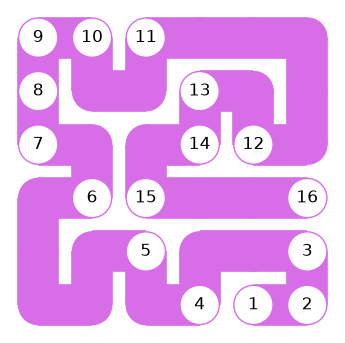

In [5]:
zip_game.solve().display()

As expected, the displayed path satisfies all the rules of Zip No. 166.

:::{figure} ../assets/how-to-solve/zip/solution.png
:label: zip-solution
:align: center
:width: 60%
Zip game solution. _Source: [LinkedIn Zip](https://www.linkedin.com/games/zip/)_
:::

---

# References

- **Miller-Tucker-Zemlin Formulation**. [AIMMS](https://how-to.aimms.com/Articles/332/332-Miller-Tucker-Zemlin-formulation.html). December 13{sup}`th`, 2024. Accessed on September 2{sup}`nd`, 2025.